# Predicting Mouse Choice from Neural Activity

## Question

Can neural activity be used to predict whether the animal makes a left or right choice?

In this notebook, we use trial-level neural activity from the IBL Brain-Wide Map dataset and train a logistic regression classifier to predict the animal's choice.

The true choices stored in the trials data are used to evaluate the prediction accuracy.

## 1. Install Required Packages

We first install the IBL packages required to access and work with the Brain-Wide Map dataset.

`ONE-api` provides access to IBL datasets, while `ibllib` contains utilities used for working with IBL data.

In [174]:
%pip install ONE-api --quiet
%pip install ibllib --quiet

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## 2. Set Up the IBL Data Interface

The IBL data are accessed through the ONE (Open Neurophysiology Environment) interface.

Here, we configure ONE to connect to the public IBL OpenAlyx server. This interface will also provide the local cache directory where the downloaded Neuromatch dataset is stored.

In [175]:
import os

# When running in Jupyter set number of threads to 1
os.environ.setdefault('ONE_HTTP_DL_THREADS', '1')

from one.api import ONE

ONE.setup(base_url='https://openalyx.internationalbrainlab.org',silent=True)

one = ONE(password='international')

Connected to https://openalyx.internationalbrainlab.org as user "intbrainlab"


## 3. Import Libraries

We import the libraries needed for data loading, manipulation, and classification.

The analysis mainly uses NumPy and pandas for data processing, SciPy for loading sparse neural activity matrices, and scikit-learn for training and evaluating the logistic regression classifier.

In [176]:
import numpy as np
import pandas as pd

from scipy import sparse
from iblutil.util import Bunch

from one.remote.aws import s3_download_file

import zipfile

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import permutation_test_score

import matplotlib.pyplot as plt



## 4. Define a Function to Download the Preprocessed Data

The Neuromatch tutorial provides preprocessed neural activity aligned to several behavioral events.

The function below downloads the requested dataset from the IBL storage and extracts it into the local ONE cache directory.

For this analysis, we will later use neural activity aligned to the animal's first movement (`firstMove`).

In [177]:
def download_data(event):
    assert event in ['firstMove', 'stimOn', 'feedback'], \
        'event must be one of "firstMove", "stimOn" or "feedback"'

    # Dataset name
    fname = f'data_{event}.zip'

    # Remote location of data
    s3_data_path = f'sample_data/Neuromatch/{fname}'

    # Local location
    save_path = one.cache_dir.joinpath('Neuromatch', fname)
    save_path.parent.mkdir(exist_ok=True, parents=True)

    # Download
    file = s3_download_file(s3_data_path, save_path)

    # Unzip
    with zipfile.ZipFile(file, 'r') as zip_ref:
        zip_ref.extractall(save_path.parent)

## 5. Locate the Downloaded Dataset

After downloading the data, we need a consistent way to locate the corresponding folder in the ONE cache.

This helper function returns the local path for a dataset aligned to a specified behavioral event.

In [178]:
def get_data_path(event):
    return one.cache_dir.joinpath('Neuromatch',f'data_{event}')

## 6. Load Dataset Metadata

The dataset contains several metadata tables describing the recorded neurons, trials, and recording sessions.

We also load the time vector associated with the neural activity. These timestamps specify the neural activity bins relative to the alignment event.

The resulting metadata object contains:

- cluster information,
- trial information,
- session information,
- time bins,
- sampling interval,
- and the local data path.

In [179]:
def load_metadata(event):

    metadata = Bunch()

    data_path = get_data_path(event)

    metadata['clusters'] = pd.read_parquet(data_path.joinpath('clusters.pqt'))

    metadata['trials'] = pd.read_parquet(data_path.joinpath('trials.pqt'))

    metadata['sessions'] = pd.read_parquet(data_path.joinpath('sessions.pqt'))

    metadata['times'] = np.load(data_path.joinpath('t.npy'))

    metadata['nbins'] = metadata['times'].size

    metadata['dt'] = np.round(np.median(np.diff(metadata['times'])),2)

    metadata['data_path'] = data_path

    return metadata

## 7. Load Trial-Level Neural Activity

For each probe insertion, neural activity is stored as a sparse PSTH matrix.

The following function loads this matrix, converts it to a dense array, and reshapes it into:

**trials × neurons × time bins**

This representation allows us to examine the activity of every recorded neuron on every behavioral trial.

In [180]:
def load_psth(data_path, pid, nbins=150):

    psth = sparse.load_npz(data_path.joinpath(f'{pid}.npz')).toarray()

    psth = psth.reshape(psth.shape[0],-1,nbins)

    return psth

## 8. Load Neural and Behavioral Data for One Probe Insertion

For the decoding analysis, neural activity and behavioral choices must correspond to the same recording session.

This helper function loads the PSTH for one probe insertion and matches it with:

- the recorded cluster information,
- the corresponding session,
- and the trial-level behavioral data.

The function returns three objects:

`psth` — trial-level neural activity  
`clust_df` — information about the recorded neurons  
`trials_df` — behavioral information for each trial

In [181]:
def get_psth_for_insertion(pid, meta, reg=None, uuids=None):

    df = meta.clusters[meta.clusters['pid'] == pid]

    df = df[['acronym', 'pid', 'uuids', 'cluster_id', 'psth_index']]

    sp = load_psth(meta.data_path,pid,nbins=meta.nbins)

    if reg is not None:
        in_reg = df['acronym'] == reg
        sp = sp[:, in_reg.values, :]
        df = df[in_reg].reset_index(drop=True)

    if uuids is not None:
        in_uuid = df['uuids'].isin(uuids)
        sp = sp[:, in_uuid.values, :]
        df = df[in_uuid].reset_index(drop=True)

    eid = meta.sessions[meta.sessions['pid'] == pid].iloc[0]['eid']

    trials = meta.trials[meta.trials['eid'] == eid].reset_index(drop=True)

    psth = sp / meta['dt']

    return psth, df, trials

## 9. Download Neural Activity Aligned to First Movement

Our goal is to predict the animal's choice from neural activity immediately before the choice-related movement occurs.

Therefore, we use the dataset aligned to `firstMove`, where time zero corresponds to the animal's first detected movement on each trial.

In [182]:
download_data('firstMove')

## 10. Load the First-Movement Metadata

We now load the metadata associated with the `firstMove` dataset.

We also inspect the time vector and bin size to understand the temporal range of neural activity available around the movement event.

In [183]:
meta = load_metadata('firstMove')
print(meta.times.shape)
print(meta.times[0], meta.times[-1])
print(meta.dt)

(150,)
-0.495 0.995
0.01


## 11. Select a Probe Insertion

To build a simple baseline decoder, we begin with a single probe insertion.

We use the same example probe insertion used in the reference tutorial and load both its neural activity and the corresponding behavioral trials.

In [184]:
pid = '8ca1a850-26ef-42be-8b28-c2e2d12f06d6'
psth, clust_df, trials_df = get_psth_for_insertion(pid,meta)

In [185]:
counts_check = psth * meta['dt']

integer_error = np.max(
    np.abs(counts_check - np.round(counts_check))
)

print("Maximum deviation from integer spike counts:",
      integer_error)

Maximum deviation from integer spike counts: 0.0


## 12. Inspect the Loaded Data

Before constructing the classifier, we inspect the dimensions of the neural and behavioral data.

The number of trials in the PSTH should correspond to the number of rows in the trial table, while the second PSTH dimension represents the recorded neural clusters.

In [186]:
print("PSTH shape:", psth.shape)
print("Number of clusters:", len(clust_df))
print("Number of trials:", len(trials_df))





PSTH shape: (569, 172, 150)
Number of clusters: 172
Number of trials: 569


In [187]:
trials_df.head()

,eid,probabilityLeft,feedbackType,contrastLeft,contrastRight,choice,psth_index,block,block_trial_number
0,15763234-d21e-491f-a01b-1238eb96d389,0.5,1.0,NaN,1.0,-1.0,0,0,0
1,15763234-d21e-491f-a01b-1238eb96d389,0.5,1.0,0.125,NaN,1.0,1,0,1
2,15763234-d21e-491f-a01b-1238eb96d389,0.5,1.0,1.000,NaN,1.0,2,0,2
3,15763234-d21e-491f-a01b-1238eb96d389,0.5,1.0,0.125,NaN,1.0,3,0,3
4,15763234-d21e-491f-a01b-1238eb96d389,0.5,1.0,NaN,1.0,-1.0,4,0,7


In [188]:
clust_df.head()

,acronym,pid,uuids,cluster_id,psth_index
73620,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,94a99b56-a69e-4b82-871e-1a869521a57a,0,0
73621,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,0a54cfe9-d78b-4447-adef-ae0352fbdc03,18,1
73622,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,7af4a528-42d0-45cd-a26a-5efa8871b56c,25,2
73623,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,96fa5343-d325-46e8-a572-32c053f05ee2,26,3
73624,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,6185cfae-98dd-4eb0-81d5-11b5ccca5e22,27,4


## 13. Inspect the Choice Labels

The target variable for our classifier is the animal's choice on each trial.

The `choice` column in the trials table contains the behavioral choice labels. We inspect their distribution before training the classifier.

In [189]:
trials_df['choice'].value_counts()

choice
 1.0    388
-1.0    181
Name: count, dtype: int64

## 14. Select Neural Activity Before Movement

To predict the animal's upcoming choice, we focus on neural activity occurring before the movement itself.

Following the reference tutorial, we select the 100 ms period immediately preceding the first movement:

**-100 ms to 0 ms relative to first movement**

This prevents the model from using neural activity occurring after movement onset.

In [190]:
time_mask = np.bitwise_and(meta.times < 0,meta.times > -0.1)

print(meta.times[time_mask])

[-0.095 -0.085 -0.075 -0.065 -0.055 -0.045 -0.035 -0.025 -0.015 -0.005]


## 15. Construct the Neural Feature Matrix

The PSTH initially has three dimensions:

**trials × neurons × time**

Logistic regression requires a two-dimensional feature matrix:

**samples × features**

We therefore average the neural activity across the selected 100 ms time window.

After averaging, each trial is represented by one feature value per recorded neuron. Thus, every row of `X` represents one trial and every column represents one neuron.

In [191]:
X = psth[:, :, time_mask].mean(axis=2)

print("Original PSTH:", psth.shape)
print("Model input X:", X.shape)

Original PSTH: (569, 172, 150)
Model input X: (569, 172)


In [192]:
y = trials_df.choice.values

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", np.unique(y))
assert X.shape[0] == y.shape[0]

X shape: (569, 172)
y shape: (569,)
Classes: [-1.  1.]


### 15.1. Test Causal Smoothing of Neural Activity

To examine whether temporal smoothing improves decoding, we create a second version of the neural features using causal exponential smoothing.

The causal kernel uses only the current and previous time bins, preventing neural activity after the first movement from leaking into the pre-movement features.

The smoothed and unsmoothed features will later be compared using exactly the same cross-validation splits.

In [193]:
from scipy.signal import lfilter

# Keep the original unsmoothed features
X_raw = X.copy()

# Causal exponential smoothing
tau = 0.02  # 20 ms
dt = meta['dt']

kernel_length = int(5 * tau / dt)

kernel = np.exp(
    -np.arange(kernel_length) * dt / tau
)

kernel = kernel / kernel.sum()

# Smooth along the time dimension only
psth_smooth = lfilter(
    kernel,
    [1.0],
    psth,
    axis=2
)

# Create features from the same -100 ms to 0 ms window
X_smooth = psth_smooth[:, :, time_mask].mean(axis=2)

print("Raw X shape:", X_raw.shape)
print("Smoothed X shape:", X_smooth.shape)

Raw X shape: (569, 172)
Smoothed X shape: (569, 172)


## 16.1. Check for Missing Values

Before splitting the data into training and test sets, we check whether the neural feature matrix (`X`) or the choice labels (`y`) contain missing values.

Some columns in the trial metadata, such as `contrastLeft` and `contrastRight`, contain NaN values. However, these NaNs are part of the task structure and these variables are not used as inputs to the current classifier.

The current model only uses:

- `X`: neural activity features
- `y`: the animal's left/right choice

Therefore, we only need to verify that these two variables do not contain missing values.

In [194]:
print("NaNs in neural features (X):", np.isnan(X).sum())
print("NaNs in choice labels (y):", np.isnan(y).sum())

assert not np.isnan(X).any(), "X contains NaN values"
assert not np.isnan(y).any(), "y contains NaN values"

nan_counts = trials_df.isna().sum()

print("Columns containing NaN values:")
print(nan_counts[nan_counts > 0])

NaNs in neural features (X): 0
NaNs in choice labels (y): 0
Columns containing NaN values:
contrastLeft     217
contrastRight    352
dtype: int64


### 16.2. Choice Modulation Index

Before training the decoder, we first ask whether individual neurons show different activity depending on the animal's upcoming choice.

For each neuron, we compare its mean activity during the 100 ms period before movement for left-choice and right-choice trials.

Following the modulation-index idea used in the reference tutorial, we define the choice modulation index as:

$$
\mathrm{Choice\ MI}
=
\frac{
\left| FR_{\mathrm{right}} - FR_{\mathrm{left}} \right|
}{
\left| FR_{\mathrm{right}} + FR_{\mathrm{left}} \right|
}
$$

where:

- $FR_{\mathrm{right}}$ is the mean pre-movement activity for right-choice trials.
- $FR_{\mathrm{left}}$ is the mean pre-movement activity for left-choice trials.

A value close to zero indicates similar activity for the two choices, whereas a larger value indicates stronger choice-related modulation.

This analysis is descriptive and is separate from the logistic-regression decoding analysis below.

In [195]:
# Mean activity for each neuron on left- and right-choice trials
left_mean = X[y == -1].mean(axis=0)
right_mean = X[y == 1].mean(axis=0)

# Choice modulation index
denominator = np.abs(left_mean + right_mean)

choice_mi = np.divide(
    np.abs(right_mean - left_mean),
    denominator,
    out=np.zeros_like(denominator, dtype=float),
    where=denominator > 0
)

# Store results alongside cluster metadata
choice_df = clust_df.copy()

choice_df['left_mean'] = left_mean
choice_df['right_mean'] = right_mean
choice_df['choice_mi'] = choice_mi

choice_df.sort_values(
    'choice_mi',
    ascending=False
).head(10)

,acronym,pid,uuids,cluster_id,psth_index,left_mean,right_mean,choice_mi
73765,SSp-tr,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,4fcdc326-92b6-4c93-bc57-3af3c8d698be,725,145,0.000000,0.128866,1.000000
73761,CA1,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,5fc661ae-4d87-4058-a238-04c32f396331,684,141,0.000000,0.798969,1.000000
73778,SSp-tr,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,dbd0c485-8045-4049-b0da-05fc6898f0c7,779,158,3.425414,0.695876,0.662302
73680,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,8b120c40-8f55-48c6-a064-d925a553afee,285,60,35.248619,9.948454,0.559774
73631,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,44b8541b-0959-497c-a2e2-1653d4b40580,48,11,0.441989,0.154639,0.481623
73747,CA3,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,fd8bdfa0-e065-4e17-a925-99ddd1954830,518,127,0.441989,0.154639,0.481623
73763,CA1,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,b9b7db43-d9d4-428f-99a9-25e150ec5d08,692,143,0.055249,0.154639,0.473541
73726,LD,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,980427b8-00e4-42ea-ab44-a51189c7446f,444,106,0.220994,0.567010,0.439104
73677,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,99904206-9ba7-4554-ae6e-cbe97d88c4e3,275,57,0.607735,1.520619,0.428916
73776,SSp-tr,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,12330fd2-603b-4a52-a8d0-ef48c9e2e6a0,773,156,0.607735,0.257732,0.404409


### 16.3. Test Choice Modulation Against a Shuffled Null Distribution

A high modulation index alone does not prove that the neuron is genuinely related to choice.

To estimate how much modulation could occur by chance, we repeatedly shuffle the left/right choice labels while keeping the neural activity unchanged.

For each neuron, the observed choice MI is compared with a null distribution obtained from shuffled choice labels.

We then calculate an empirical permutation p-value and apply a false-discovery-rate (FDR) correction across neurons.

In [196]:
rng = np.random.default_rng(0)

n_permutations = 1000
n_neurons = X.shape[1]

null_mi = np.zeros(
    (n_permutations, n_neurons)
)

for i in range(n_permutations):

    # Shuffle choice labels
    y_shuffled = rng.permutation(y)

    left_shuffled = X[y_shuffled == -1].mean(axis=0)
    right_shuffled = X[y_shuffled == 1].mean(axis=0)

    denominator = np.abs(
        left_shuffled + right_shuffled
    )

    null_mi[i] = np.divide(
        np.abs(right_shuffled - left_shuffled),
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator > 0
    )

In [197]:
# Empirical permutation p-values
observed_mi = choice_df['choice_mi'].values

p_values = (
    1 +
    (null_mi >= observed_mi).sum(axis=0)
) / (n_permutations + 1)


# Benjamini-Hochberg FDR correction
def fdr_bh(p_values):

    p_values = np.asarray(p_values)

    order = np.argsort(p_values)
    ranked_p = p_values[order]

    m = len(p_values)

    q_ranked = (
        ranked_p * m /
        np.arange(1, m + 1)
    )

    q_ranked = np.minimum.accumulate(
        q_ranked[::-1]
    )[::-1]

    q_values = np.empty(m)

    q_values[order] = np.clip(
        q_ranked,
        0,
        1
    )

    return q_values


q_values = fdr_bh(p_values)

choice_df['p_perm'] = p_values
choice_df['q_fdr'] = q_values

choice_df['significant_choice_modulation'] = (
    choice_df['q_fdr'] < 0.05
)

print(
    "Significantly choice-modulated neurons:",
    choice_df['significant_choice_modulation'].sum(),
    "/",
    len(choice_df)
)

Significantly choice-modulated neurons: 57 / 172


In [198]:
choice_df[
    [
        'acronym',
        'cluster_id',
        'choice_mi',
        'p_perm',
        'q_fdr',
        'significant_choice_modulation'
    ]
].sort_values(
    'choice_mi',
    ascending=False
).head(15)

,acronym,cluster_id,choice_mi,p_perm,q_fdr,significant_choice_modulation
73765,SSp-tr,725,1.000000,0.142857,0.245714,False
73761,CA1,684,1.000000,0.000999,0.005925,True
73778,SSp-tr,779,0.662302,0.000999,0.005925,True
73680,PO,285,0.559774,0.000999,0.005925,True
73631,PO,48,0.481623,0.069930,0.156207,False
73747,CA3,518,0.481623,0.316683,0.442842,False
73763,CA1,692,0.473541,0.556444,0.678782,False
73726,LD,444,0.439104,0.166833,0.274925,False
73677,PO,275,0.428916,0.034965,0.089761,False
73776,SSp-tr,773,0.404409,0.128871,0.235807,False


### 16.4. Summarize Choice Modulation by Brain Region

Each recorded neuron is associated with a brain-region acronym.

We therefore group the neurons from the current probe insertion by brain region and summarize:

- the number of recorded neurons,
- the median choice modulation index,
- and the proportion of neurons that remain significant after FDR correction.

Because a single probe insertion may contain only a small number of neurons from some regions, these results should be treated as exploratory. A brain-wide analysis across many insertions will be performed later.

In [199]:
insertion_region_summary = (
    choice_df
    .groupby('acronym')
    .agg(
        n_clusters=('choice_mi', 'size'),
        median_choice_mi=('choice_mi', 'median'),
        mean_choice_mi=('choice_mi', 'mean'),
        significant_fraction=(
            'significant_choice_modulation',
            'mean'
        )
    )
    .sort_values(
        'median_choice_mi',
        ascending=False
    )
)

insertion_region_summary

,n_clusters,median_choice_mi,mean_choice_mi,significant_fraction
acronym,,,,
CA3,8,0.260358,0.284562,0.500000
SSp-tr,18,0.228507,0.265383,0.333333
CA1,10,0.139752,0.219262,0.100000
root,1,0.128772,0.128772,0.000000
LD,47,0.112334,0.140153,0.319149
PO,86,0.098350,0.129875,0.348837
CA2,2,0.051174,0.051174,0.500000


## 17. Split the Data into Training and Test Sets

To evaluate whether the model can predict choices on unseen trials, we divide the data into separate training and test sets.

Following the simple baseline approach in the tutorial, 50% of the trials are used for training and the remaining 50% are held out for testing.

The random state is fixed to make the split reproducible.

In [200]:
# X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# print("Training samples:", X_train.shape[0])
# print("Testing samples:", X_test.shape[0])

trial_indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    trial_indices,
    test_size=0.5,
    random_state=0,
    stratify=y
)

# Original features
X_train = X_raw[train_idx]
X_test = X_raw[test_idx]

# Smoothed features
X_train_smooth = X_smooth[train_idx]
X_test_smooth = X_smooth[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("Training trials:", len(train_idx))
print("Testing trials:", len(test_idx))

Training trials: 284
Testing trials: 285


### 17.3. Cross-Validation on the Training Data

Before fitting the final logistic regression model, we use cross-validation to obtain a more reliable estimate of its performance.

We use 5-fold stratified cross-validation on the training set only. In each fold, the preprocessing steps and logistic regression model are fitted using only the training portion of that fold and evaluated on the remaining validation portion.

The held-out test set is not used during cross-validation and will be used only once for the final evaluation.

In [201]:
# Define the complete modeling pipeline
cv_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
        random_state=0,
        max_iter=5000
    ))
])

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

cv_scores = cross_val_score(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

print("Accuracy for each fold:", cv_scores)
print(f"Mean CV accuracy: {cv_scores.mean():.3f}")
print(f"CV standard deviation: {cv_scores.std():.3f}")

Accuracy for each fold: [0.78947368 0.8245614  0.84210526 0.78947368 0.82142857]
Mean CV accuracy: 0.813
CV standard deviation: 0.021


In [202]:
raw_cv_scores = cross_val_score(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

smooth_cv_scores = cross_val_score(
    cv_pipeline,
    X_train_smooth,
    y_train,
    cv=cv,
    scoring='accuracy'
)

print(
    f"Raw mean CV accuracy: "
    f"{raw_cv_scores.mean():.3f}"
)

print(
    f"Smoothed mean CV accuracy: "
    f"{smooth_cv_scores.mean():.3f}"
)

print(
    f"Difference: "
    f"{(smooth_cv_scores - raw_cv_scores).mean():.3f}"
)

Raw mean CV accuracy: 0.813
Smoothed mean CV accuracy: 0.817
Difference: 0.004


### 17.4. 95% Confidence Interval and Dummy Baseline Comparison

To evaluate whether the logistic regression model consistently performs better than a simple baseline, we compare both models using the same cross-validation splits.

We use repeated stratified 5-fold cross-validation to obtain multiple performance estimates.

For each split, we calculate the difference between logistic regression accuracy and dummy-model accuracy. We then estimate a 95% confidence interval for this accuracy gain.

If the entire confidence interval is above zero, this provides evidence that the neural decoder performs consistently better than the dummy baseline.

In [203]:
# Repeated stratified cross-validation
repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=20,
    random_state=0
)

# Save exactly the same splits for both models
cv_splits = list(
    repeated_cv.split(X_train, y_train)
)

# Logistic Regression scores
logistic_cv_scores = cross_val_score(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring='accuracy'
)

# Dummy baseline
dummy_cv = DummyClassifier(
    strategy='most_frequent'
)

dummy_cv_scores = cross_val_score(
    dummy_cv,
    X_train,
    y_train,
    cv=cv_splits,
    scoring='accuracy'
)

print("Mean Logistic CV Accuracy:",
      logistic_cv_scores.mean())

print("Mean Dummy CV Accuracy:",
      dummy_cv_scores.mean())

Mean Logistic CV Accuracy: 0.8158583959899748
Mean Dummy CV Accuracy: 0.6830827067669173


In [204]:
accuracy_gain = (
    logistic_cv_scores -
    dummy_cv_scores
)

print(
    "Mean accuracy gain:",
    accuracy_gain.mean()
)

Mean accuracy gain: 0.1327756892230576


In [205]:
rng = np.random.default_rng(0)

n_bootstrap = 10000

bootstrap_means = np.empty(
    n_bootstrap
)

for i in range(n_bootstrap):

    bootstrap_sample = rng.choice(
        accuracy_gain,
        size=len(accuracy_gain),
        replace=True
    )

    bootstrap_means[i] = (
        bootstrap_sample.mean()
    )

ci_lower, ci_upper = np.percentile(
    bootstrap_means,
    [2.5, 97.5]
)

print(
    f"Mean Accuracy Gain: "
    f"{accuracy_gain.mean():.3f}"
)

print(
    f"95% CI for Accuracy Gain: "
    f"[{ci_lower:.3f}, {ci_upper:.3f}]"
)

Mean Accuracy Gain: 0.133
95% CI for Accuracy Gain: [0.124, 0.141]


In [206]:
if ci_lower > 0:

    print(
        "The logistic regression model "
        "consistently outperforms the "
        "dummy baseline."
    )

else:

    print(
        "The 95% confidence interval "
        "includes zero, so the model's "
        "improvement over the dummy "
        "baseline is not clearly established."
    )

The logistic regression model consistently outperforms the dummy baseline.


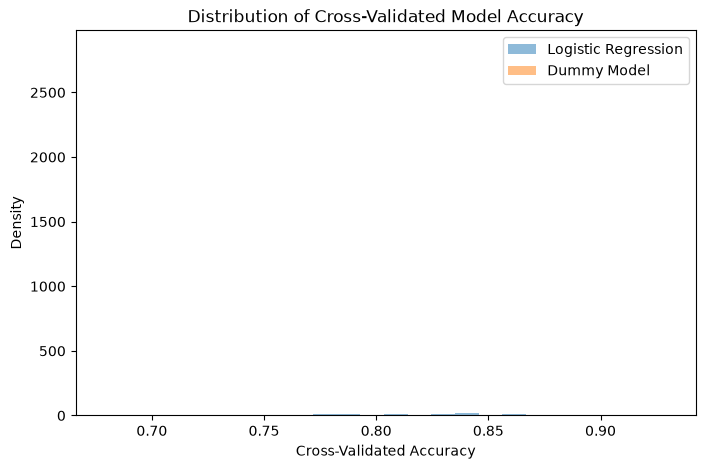

In [207]:
plt.figure(figsize=(8, 5))

plt.hist(
    logistic_cv_scores,
    bins=20,
    density=True,
    alpha=0.5,
    label='Logistic Regression'
)

plt.hist(
    dummy_cv_scores,
    bins=20,
    density=True,
    alpha=0.5,
    label='Dummy Model'
)

plt.xlabel('Cross-Validated Accuracy')
plt.ylabel('Density')
plt.title('Distribution of Cross-Validated Model Accuracy')

plt.legend()
plt.show()

### 17.5. Permutation Test for Decoding Significance

To test whether the decoding accuracy is genuinely related to the relationship between neural activity and choice, we perform a permutation test.

The true choice labels are randomly shuffled while the neural features remain unchanged. The complete cross-validation procedure is then repeated using these shuffled labels.

This creates a null distribution representing the decoding accuracy expected when there is no real relationship between neural activity and the animal's choice.

The observed cross-validated accuracy is compared with this null distribution. A small permutation p-value indicates that the decoding performance is unlikely to have occurred by chance.

In [208]:
observed_score, permutation_scores, permutation_pvalue = permutation_test_score(
    cv_pipeline,
    X_train,
    y_train,
    scoring='accuracy',
    cv=cv,
    n_permutations=1000,
    n_jobs=-1,
    random_state=0
)

print(f"Observed CV Accuracy: {observed_score:.3f}")
print(f"Mean Permuted Accuracy: {permutation_scores.mean():.3f}")
print(f"Permutation p-value: {permutation_pvalue:.4f}")

Observed CV Accuracy: 0.813
Mean Permuted Accuracy: 0.560
Permutation p-value: 0.0010


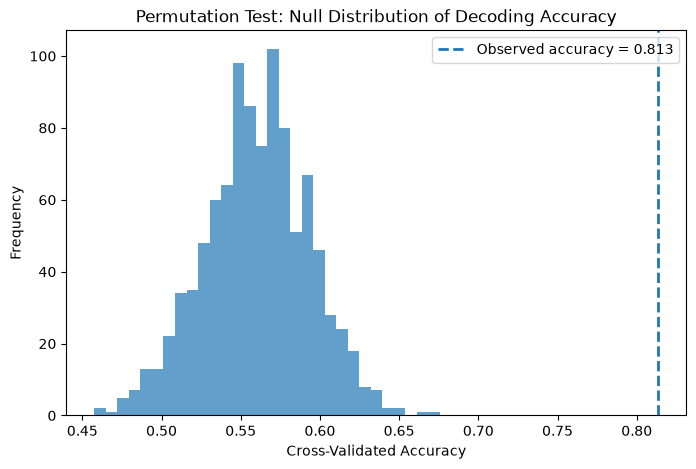

In [209]:
plt.figure(figsize=(8, 5))

plt.hist(
    permutation_scores,
    bins=30,
    alpha=0.7
)

plt.axvline(
    observed_score,
    linestyle='--',
    linewidth=2,
    label=f'Observed accuracy = {observed_score:.3f}'
)

plt.xlabel('Cross-Validated Accuracy')
plt.ylabel('Frequency')
plt.title('Permutation Test: Null Distribution of Decoding Accuracy')
plt.legend()

plt.show()

In [210]:
alpha = 0.05

if permutation_pvalue < alpha:
    print(
        "Decoding accuracy is significantly above the shuffled-label null distribution."
    )
else:
    print(
        "Decoding accuracy is not significantly different from the shuffled-label null distribution."
    )

Decoding accuracy is significantly above the shuffled-label null distribution.


## 18. Train a Logistic Regression Classifier

We now train a logistic regression classifier using the neural activity from the training trials.

The model learns a weight for each neural feature and uses the resulting combination of neural activity to distinguish between the two behavioral choices.

In [211]:
clf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
        random_state=0,
        max_iter=5000
    ))
])

# Train final model using all training trials
clf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[-1., 1.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,172
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note tha

## 18.1. Define Dummy Baseline Models

Before evaluating the logistic regression classifier, we establish simple baseline models that do not use the neural activity in a meaningful way.

These baselines help determine whether the neural decoder performs better than trivial prediction strategies.

We use two dummy classifiers:

- **Most Frequent:** always predicts the most common choice observed in the training set.
- **Stratified Random:** generates predictions randomly while approximately preserving the class distribution observed in the training data.

A useful neural decoder should perform substantially better than these baselines.

In [212]:
dummy_most_frequent = DummyClassifier(strategy='most_frequent')

dummy_stratified = DummyClassifier(strategy='stratified',random_state=0)

dummy_most_frequent.fit(X_train, y_train)
dummy_stratified.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'stratified'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.32,0.68]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[float64](2,)","[-1., 1.]"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,172
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


## 19. Predict Choices on Unseen Trials

After training, we apply the classifier to the held-out test trials.

The predicted labels can then be directly compared with the animal's true choices stored in `y_test`.

In [213]:
choice_predicted = clf.predict(X_test)

dummy_most_predicted = dummy_most_frequent.predict(X_test)

dummy_stratified_predicted = dummy_stratified.predict(X_test)

print("True choices:")
print(y_test[:20])

print()

print("Predicted choices:")
print(choice_predicted[:20])

True choices:
[-1.  1. -1.  1. -1. -1. -1.  1. -1. -1.  1. -1.  1. -1.  1.  1.  1.  1.
  1. -1.]

Predicted choices:
[-1.  1.  1.  1. -1.  1. -1.  1. -1. -1.  1. -1.  1. -1.  1. -1.  1.  1.
  1. -1.]


## 20. Evaluate the Decoder Against Dummy Baselines

To determine whether the neural activity contains meaningful information about the animal's choice, we compare the logistic regression classifier with the dummy baseline models.

All models are evaluated on exactly the same held-out test trials.

If logistic regression achieves higher accuracy than the dummy classifiers, this suggests that the neural population activity contains predictive information about the animal's upcoming choice.

In [214]:
logistic_accuracy = accuracy_score(y_test,choice_predicted)

most_frequent_accuracy = accuracy_score(y_test,dummy_most_predicted)

stratified_accuracy = accuracy_score(y_test,dummy_stratified_predicted)

print(f"Logistic Regression Accuracy: {logistic_accuracy:.2%}")
print(f"Most Frequent Dummy Accuracy: {most_frequent_accuracy:.2%}")
print(f"Stratified Dummy Accuracy: {stratified_accuracy:.2%}")

Logistic Regression Accuracy: 81.05%
Most Frequent Dummy Accuracy: 68.07%
Stratified Dummy Accuracy: 58.60%


## Conclusion

In this baseline analysis, neural activity recorded immediately before the animal's first movement was used to predict its left/right choice.

Each trial was represented by the average activity of the recorded neurons during the 100 ms period preceding movement onset. A logistic regression classifier was then trained on a subset of trials and evaluated on held-out trials.

The resulting test accuracy provides a simple measure of how much information about the animal's upcoming choice is present in the recorded neural population activity.

In [215]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Most Frequent Dummy',
        'Stratified Dummy'
    ],
    'Accuracy': [
        logistic_accuracy,
        most_frequent_accuracy,
        stratified_accuracy
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.810526
1,Most Frequent Dummy,0.680702
2,Stratified Dummy,0.585965


# Extension A: Brain-Wide Choice Modulation Analysis

The previous analysis examined choice modulation within a single probe insertion.

We now extend the same idea across the Brain-Wide Map dataset.

For every probe insertion, we calculate the choice modulation index of each neuron using neural activity during the 100 ms period preceding first movement.

Each neuron's modulation is calculated within its own recording session before neurons are pooled by anatomical brain region.

This avoids directly combining trials from different animals or sessions.

In [216]:
all_choice_mi = []

pids = meta.clusters['pid'].unique()

for pid_i in pids:

    psth_i, clust_i, trials_i = get_psth_for_insertion(
        pid_i,
        meta
    )

    # Same pre-movement feature window used by the decoder
    X_i = psth_i[:, :, time_mask].mean(axis=2)

    y_i = trials_i.choice.values

    # Keep only valid left/right choices
    valid_trials = np.isin(y_i, [-1, 1])

    X_i = X_i[valid_trials]
    y_i = y_i[valid_trials]

    # Need both choices to calculate choice modulation
    if len(np.unique(y_i)) < 2:
        continue

    left_mean_i = X_i[y_i == -1].mean(axis=0)
    right_mean_i = X_i[y_i == 1].mean(axis=0)

    denominator = np.abs(
        left_mean_i + right_mean_i
    )

    mi_i = np.divide(
        np.abs(right_mean_i - left_mean_i),
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator > 0
    )

    temp = clust_i.copy()

    temp['choice_mi'] = mi_i

    all_choice_mi.append(temp)


all_choice_mi = pd.concat(
    all_choice_mi,
    ignore_index=True
)

print(
    "Total neurons analyzed:",
    len(all_choice_mi)
)

Total neurons analyzed: 75708


## Brain-Region Summary

Following the general brain-wide analysis strategy used in the reference tutorial, we now summarize neural modulation by anatomical region.

For each region, we calculate:

- the total number of recorded neurons,
- the median choice MI,
- the mean choice MI,
- and the fraction of neurons with a relatively high choice MI.

The MI threshold of 0.3 is used here only as a descriptive heuristic, similar to the tutorial. It should not be interpreted as statistical significance.

In [217]:
mi_threshold = 0.3

all_choice_mi['high_choice_mi'] = (
    (all_choice_mi['choice_mi'] >= mi_threshold) &
    (all_choice_mi['choice_mi'] < 1)
)

brain_region_summary = (
    all_choice_mi
    .groupby('acronym')
    .agg(
        n_clusters=('choice_mi', 'size'),
        median_choice_mi=('choice_mi', 'median'),
        mean_choice_mi=('choice_mi', 'mean'),
        high_mi_fraction=('high_choice_mi', 'mean')
    )
)

brain_region_summary.head()

,n_clusters,median_choice_mi,mean_choice_mi,high_mi_fraction
acronym,,,,
AAA,25,0.049431,0.092883,0.120000
ACAd,369,0.132462,0.190134,0.162602
ACAv,195,0.103154,0.150953,0.117949
ACB,340,0.111226,0.172033,0.155882
AD,15,0.048214,0.073891,0.000000


## Restrict the Analysis to Well-Sampled Brain Regions

Regions represented by only a small number of neurons can show unstable or misleading modulation estimates.

Following the reference tutorial, we restrict the descriptive brain-wide comparison to regions containing at least 200 recorded clusters.

In [218]:
min_clusters = 200

brain_region_filtered = (
    brain_region_summary[
        brain_region_summary['n_clusters'] >= min_clusters
    ]
    .sort_values(
        'high_mi_fraction',
        ascending=False
    )
)

brain_region_filtered.head(20)

,n_clusters,median_choice_mi,mean_choice_mi,high_mi_fraction
acronym,,,,
GRN,560,0.152504,0.241648,0.267857
VISam,374,0.143269,0.237423,0.232620
PRNr,770,0.138244,0.220633,0.231169
IRN,744,0.149193,0.224250,0.229839
PL,420,0.145808,0.239596,0.221429
SSp-tr,303,0.150436,0.225040,0.214521
MOs,1293,0.147607,0.212579,0.214230
SCm,1666,0.128583,0.210997,0.211885
ORBvl,669,0.121504,0.199286,0.204783


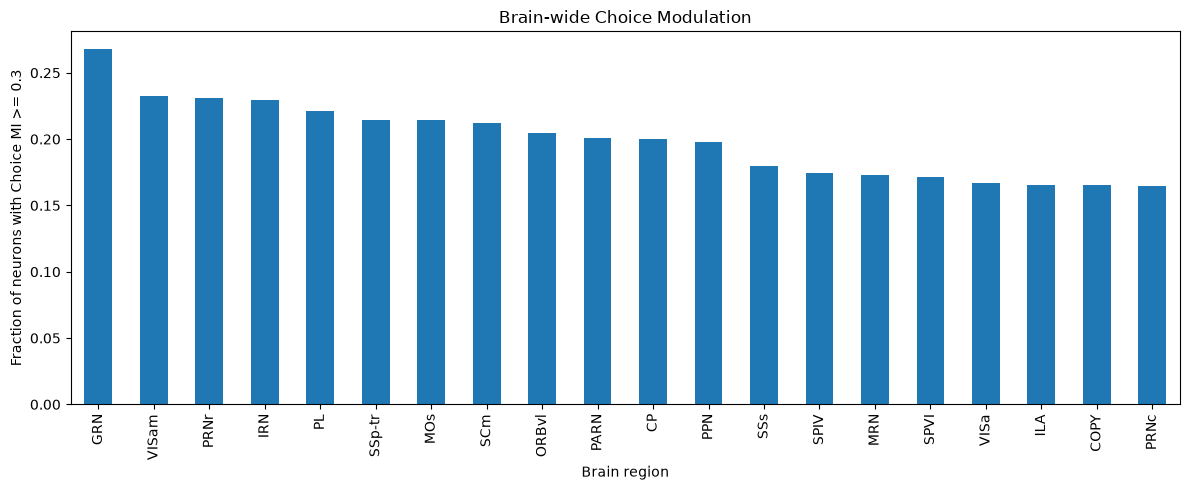

In [219]:
top_regions = brain_region_filtered.head(20)

ax = top_regions['high_mi_fraction'].plot(
    kind='bar',
    figsize=(12, 5)
)

ax.set_xlabel('Brain region')
ax.set_ylabel('Fraction of neurons with Choice MI >= 0.3')
ax.set_title('Brain-wide Choice Modulation')

plt.tight_layout()
plt.show()

# Extension B: Region-Wise Choice Decoding

Choice modulation measures whether neural activity differs between left and right choices, but the main question of this project is predictive:

**Can neural activity predict the animal's upcoming choice?**

We therefore train separate logistic-regression decoders for individual brain regions.

Importantly, decoding is performed separately within each probe insertion. We do not combine neurons from different sessions into a single feature matrix.

For each region-insertion pair, the logistic-regression accuracy is compared with a most-frequent dummy classifier evaluated on exactly the same test trials.

In [220]:
region_decoding_results = []

pids = meta.clusters['pid'].unique()

for pid_i in pids:

    psth_i, clust_i, trials_i = get_psth_for_insertion(
        pid_i,
        meta
    )

    # Reset cluster indices so they match the PSTH neuron axis
    clust_i = clust_i.reset_index(drop=True)

    # Sanity check: one metadata row per PSTH neuron
    assert psth_i.shape[1] == len(clust_i)

    y_i = trials_i.choice.values

    valid_trials = np.isin(y_i, [-1, 1])

    y_valid = y_i[valid_trials]

    # Skip sessions without both classes
    if len(np.unique(y_valid)) < 2:
        continue

    # Analyze each region recorded by this insertion
    for reg in clust_i['acronym'].dropna().unique():

        if reg in ['root', 'void']:
            continue

        # Positional indices of neurons belonging to this region
        cluster_indices = np.flatnonzero(
            clust_i['acronym'].to_numpy() == reg
        )

        if len(cluster_indices) < 5:
            continue

        # Require at least a few neurons
        if len(cluster_indices) < 5:
            continue

        X_reg = (
            psth_i[
                :,
                cluster_indices,
                :
            ][:, :, time_mask]
            .mean(axis=2)
        )

        X_reg = X_reg[valid_trials]

        X_train_reg, X_test_reg, y_train_reg, y_test_reg = (
            train_test_split(
                X_reg,
                y_valid,
                test_size=0.5,
                random_state=0,
                stratify=y_valid
            )
        )

        # Logistic regression
        clf_reg = LogisticRegression(
            random_state=0,
            max_iter=1000
        )

        # Scale neural features using training data only
        scaler_reg = StandardScaler()

        X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
        X_test_reg_scaled = scaler_reg.transform(X_test_reg)

        # Logistic regression
        clf_reg = LogisticRegression(
            random_state=0,
            max_iter=5000
        )

        clf_reg.fit(
            X_train_reg_scaled,
            y_train_reg
        )

        pred_reg = clf_reg.predict(
            X_test_reg_scaled
        )

        logistic_acc = accuracy_score(
            y_test_reg,
            pred_reg
        )

        # Dummy baseline
        dummy_reg = DummyClassifier(
            strategy='most_frequent'
        )

        dummy_reg.fit(
            X_train_reg,
            y_train_reg
        )

        dummy_pred = dummy_reg.predict(
            X_test_reg
        )

        dummy_acc = accuracy_score(
            y_test_reg,
            dummy_pred
        )

        region_decoding_results.append({
            'pid': pid_i,
            'acronym': reg,
            'n_clusters': len(cluster_indices),
            'logistic_accuracy': logistic_acc,
            'dummy_accuracy': dummy_acc,
            'accuracy_gain': logistic_acc - dummy_acc
        })

In [221]:
region_decoding_results = pd.DataFrame(
    region_decoding_results
)

region_decoding_results.head()

,pid,acronym,n_clusters,logistic_accuracy,dummy_accuracy,accuracy_gain
0,56f2a378-78d2-4132-b3c8-8c1ba82be598,MG,12,0.593909,0.573604,0.020305
1,56f2a378-78d2-4132-b3c8-8c1ba82be598,LGd,46,0.563452,0.573604,-0.010152
2,47be9ae4-290f-46ab-b047-952bc3a1a509,COAp,8,0.560976,0.577236,-0.016260
3,47be9ae4-290f-46ab-b047-952bc3a1a509,BMA,46,0.560976,0.577236,-0.016260
4,47be9ae4-290f-46ab-b047-952bc3a1a509,IA,10,0.609756,0.577236,0.032520


## Aggregate Decoding Performance Across Insertions

A brain region may be recorded in multiple independent probe insertions.

Rather than combining these recordings into one artificial neural population, we summarize the decoding performance obtained independently from each insertion.

For each region, we report the median logistic-regression accuracy, the median dummy accuracy, and the median improvement over the dummy baseline.

In [222]:
region_decoding_summary = (
    region_decoding_results
    .groupby('acronym')
    .agg(
        n_insertions=('pid', 'nunique'),

        median_accuracy=(
            'logistic_accuracy',
            'median'
        ),

        median_dummy_accuracy=(
            'dummy_accuracy',
            'median'
        ),

        median_accuracy_gain=(
            'accuracy_gain',
            'median'
        ),

        median_n_clusters=(
            'n_clusters',
            'median'
        )
    )
)

In [223]:
region_decoding_filtered = (
    region_decoding_summary[
        region_decoding_summary['n_insertions'] >= 3
    ]
    .sort_values(
        'median_accuracy_gain',
        ascending=False
    )
)

region_decoding_filtered.head(20)

,n_insertions,median_accuracy,median_dummy_accuracy,median_accuracy_gain,median_n_clusters
acronym,,,,,
GRN,14,0.813365,0.565069,0.242653,31.5
SNr,10,0.734663,0.544302,0.205096,10.5
PRNr,20,0.752533,0.552754,0.182918,39.5
RPF,4,0.766379,0.570736,0.171264,11.0
MA,3,0.681159,0.536232,0.144928,11.0
IRN,27,0.688889,0.560000,0.143541,28.0
SSp-ul,8,0.703640,0.545560,0.142486,15.5
MARN,3,0.746324,0.606618,0.139706,23.0
MDRN,7,0.773869,0.556291,0.139535,27.0


# Extension C: Combine Choice Modulation and Decoding Results

The two analyses provide complementary information:

- **Choice MI** measures how strongly neural activity differs between left and right choices.
- **Decoding accuracy** measures how well neural population activity predicts choice on held-out trials.

We therefore combine the region-level results to identify brain regions that show both strong choice-related modulation and useful predictive information.

In [224]:
combined_region_results = (
    brain_region_filtered
    .join(
        region_decoding_filtered,
        how='inner'
    )
)

combined_region_results = (
    combined_region_results
    .sort_values(
        'median_accuracy_gain',
        ascending=False
    )
)

combined_region_results[
    [
        'n_clusters',
        'median_choice_mi',
        'high_mi_fraction',
        'n_insertions',
        'median_accuracy',
        'median_dummy_accuracy',
        'median_accuracy_gain'
    ]
].head(20)

,n_clusters,median_choice_mi,high_mi_fraction,n_insertions,median_accuracy,median_dummy_accuracy,median_accuracy_gain
acronym,,,,,,,
GRN,560,0.152504,0.267857,14,0.813365,0.565069,0.242653
PRNr,770,0.138244,0.231169,20,0.752533,0.552754,0.182918
IRN,744,0.149193,0.229839,27,0.688889,0.560000,0.143541
MRN,2678,0.106998,0.172890,110,0.727017,0.555208,0.134718
SIM,893,0.099457,0.128779,19,0.726190,0.575269,0.132653
MV,672,0.095244,0.150298,20,0.704440,0.565069,0.126330
APN,1543,0.101696,0.160078,57,0.704280,0.538168,0.115646
GPe,322,0.069885,0.096273,11,0.707937,0.577236,0.113821
SCm,1666,0.128583,0.211885,62,0.714170,0.561485,0.113521


# Extension D: Leave-One-Region-Out Ablation Analysis

To estimate how much each brain region contributes to choice decoding, we perform a leave-one-region-out ablation analysis.

For each recording insertion, we first train and evaluate a decoder using all available neurons. We then remove the neurons belonging to one brain region at a time and repeat the decoding analysis using exactly the same cross-validation splits.

The decrease in cross-validated accuracy after removing a region is used as a measure of its contribution to choice decoding.

A larger positive accuracy drop indicates that removing that region causes a stronger loss of choice-related information.

Because this is a computational ablation rather than a biological intervention, the results indicate contribution to decoding and should not be interpreted as evidence of a causal effect on behavior.

In [225]:
ablation_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
        random_state=0,
        max_iter=5000
    ))
])

ablation_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

min_clusters_per_region = 5

In [ ]:
ablation_results = []

pids = meta.clusters['pid'].dropna().unique()

for pid_i in pids:

    try:
        # Load one insertion
        psth_i, clust_i, trials_i = get_psth_for_insertion(
            pid_i,
            meta
        )

        # Important: make cluster indices positional
        clust_i = clust_i.reset_index(drop=True)

        assert psth_i.shape[1] == len(clust_i)

        # Choice labels
        y_i = trials_i.choice.values

        # Keep only valid left/right choices
        valid_trials = np.isin(y_i, [-1, 1])

        y_valid = y_i[valid_trials]

        # Need both classes
        classes, counts = np.unique(
            y_valid,
            return_counts=True
        )

        if len(classes) < 2:
            continue

        # Need enough trials for 5-fold CV
        if counts.min() < 5:
            continue

        # Neural features:
        # mean activity during -100 ms to first movement
        X_all = (
            psth_i[:, :, time_mask]
            .mean(axis=2)
        )

        X_all = X_all[valid_trials]

        # Exactly the same CV splits will be used
        # for the full and ablated models
        cv_splits = list(
            ablation_cv.split(
                X_all,
                y_valid
            )
        )

        # Full model
        full_scores = cross_val_score(
            ablation_pipeline,
            X_all,
            y_valid,
            cv=cv_splits,
            scoring='accuracy'
        )

        full_accuracy = full_scores.mean()

        # Brain regions in this insertion
        regions = (
            clust_i['acronym']
            .dropna()
            .unique()
        )

        for region in regions:

            if region in ['root', 'void']:
                continue

            region_mask = (
                clust_i['acronym']
                .to_numpy()
                == region
            )

            n_removed = region_mask.sum()

            # Ignore regions represented by very few neurons
            if n_removed < min_clusters_per_region:
                continue

            keep_mask = ~region_mask

            # Cannot decode if nothing remains
            if keep_mask.sum() == 0:
                continue

            # Remove this region
            X_without_region = X_all[:, keep_mask]

            # Same trials + same CV folds
            ablated_scores = cross_val_score(
                ablation_pipeline,
                X_without_region,
                y_valid,
                cv=cv_splits,
                scoring='accuracy'
            )

            ablated_accuracy = (
                ablated_scores.mean()
            )

            accuracy_drop = (
                full_accuracy
                - ablated_accuracy
            )

            ablation_results.append({
                'pid': pid_i,
                'acronym': region,
                'n_removed_clusters': n_removed,
                'n_total_clusters': X_all.shape[1],
                'full_accuracy': full_accuracy,
                'ablated_accuracy': ablated_accuracy,
                'accuracy_drop': accuracy_drop
            })

    except Exception as e:

        print(
            f"Skipping {pid_i}: {e}"
        )

In [227]:
ablation_results = pd.DataFrame(
    ablation_results
)

print(
    "Number of region-insertion comparisons:",
    len(ablation_results)
)

ablation_results.head()

Number of region-insertion comparisons: 2609


,pid,acronym,n_removed_clusters,n_total_clusters,full_accuracy,ablated_accuracy,accuracy_drop
0,56f2a378-78d2-4132-b3c8-8c1ba82be598,MG,12,76,0.677605,0.664882,0.012723
1,56f2a378-78d2-4132-b3c8-8c1ba82be598,LGd,46,76,0.677605,0.672639,0.004966
2,47be9ae4-290f-46ab-b047-952bc3a1a509,COAp,8,169,0.697959,0.681633,0.016327
3,47be9ae4-290f-46ab-b047-952bc3a1a509,BMA,46,169,0.697959,0.706122,-0.008163
4,47be9ae4-290f-46ab-b047-952bc3a1a509,IA,10,169,0.697959,0.710204,-0.012245


## Region-Level Ablation Summary

Because the same brain region may appear in multiple recording insertions, we summarize the ablation effect across insertions.

Regions with a consistently larger positive accuracy drop are interpreted as carrying more unique information useful for choice decoding.

In [228]:
region_ablation_summary = (
    ablation_results
    .groupby('acronym')
    .agg(
        n_insertions=(
            'pid',
            'nunique'
        ),
        median_accuracy_drop=(
            'accuracy_drop',
            'median'
        ),
        mean_accuracy_drop=(
            'accuracy_drop',
            'mean'
        ),
        median_full_accuracy=(
            'full_accuracy',
            'median'
        ),
        median_ablated_accuracy=(
            'ablated_accuracy',
            'median'
        ),
        median_removed_clusters=(
            'n_removed_clusters',
            'median'
        )
    )
    .reset_index()
)

In [229]:
region_ablation_summary = (
    ablation_results
    .groupby('acronym')
    .agg(
        n_insertions=('pid', 'nunique'),
        median_accuracy_drop=('accuracy_drop', 'median'),
        mean_accuracy_drop=('accuracy_drop', 'mean'),
        median_full_accuracy=('full_accuracy', 'median'),
        median_ablated_accuracy=('ablated_accuracy', 'median'),
        median_removed_clusters=('n_removed_clusters', 'median')
    )
    .reset_index()
)

region_ablation_summary.head()

,acronym,n_insertions,median_accuracy_drop,mean_accuracy_drop,median_full_accuracy,median_ablated_accuracy,median_removed_clusters
0,AAA,2,0.004780,0.004780,0.759965,0.755186,11.0
1,ACAd,21,0.011670,0.019719,0.679858,0.677809,15.0
2,ACAv,11,0.006546,0.004477,0.618081,0.633571,19.0
3,ACB,19,0.002778,-0.000745,0.716447,0.731274,14.0
4,AD,2,0.011442,0.011442,0.567286,0.555844,5.5


In [230]:
region_ablation_filtered = (
    region_ablation_summary[
        region_ablation_summary['n_insertions'] >= 3
    ]
    .sort_values(
        'median_accuracy_drop',
        ascending=False
    )
)

region_ablation_filtered.head(20)

,acronym,n_insertions,median_accuracy_drop,mean_accuracy_drop,median_full_accuracy,median_ablated_accuracy,median_removed_clusters
68,GPi,3,0.070000,0.050389,0.755000,0.685000,12.0
128,ORBl,7,0.037331,0.033766,0.615493,0.637343,19.0
233,VISrl,3,0.036330,0.024974,0.664036,0.636514,19.0
67,GPe,11,0.032653,0.040597,0.774074,0.729630,20.0
114,MOs,38,0.031677,0.056927,0.721855,0.641520,31.0
225,VISal,4,0.030114,0.038861,0.720765,0.677928,20.5
140,PC5,3,0.025443,0.055193,0.720795,0.636702,10.0
200,SSp-ll,6,0.024571,0.018159,0.690551,0.698368,16.5
15,APN,57,0.024440,0.045112,0.752882,0.701584,24.0
176,RPF,4,0.023379,0.015667,0.784256,0.769159,11.0


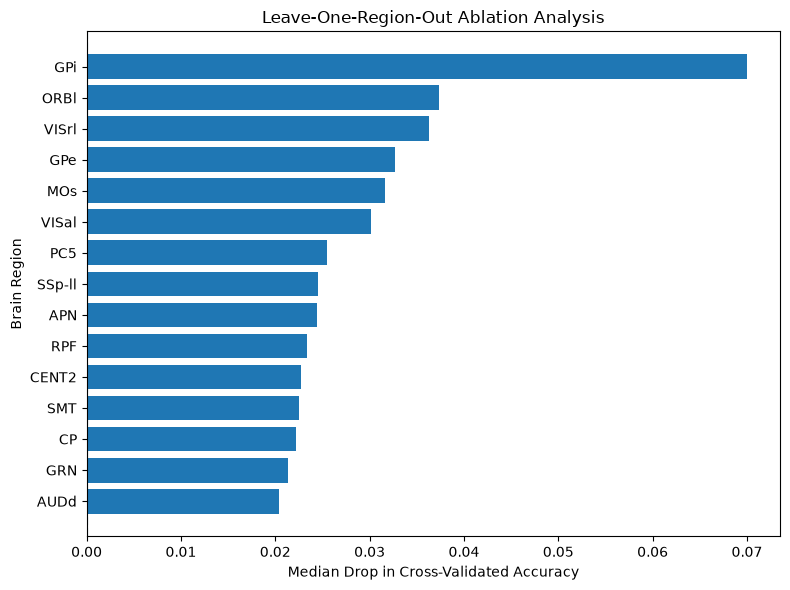

In [231]:
top_regions = (
    region_ablation_filtered
    .head(15)
    .sort_values(
        'median_accuracy_drop'
    )
)

plt.figure(figsize=(8, 6))

plt.barh(
    top_regions['acronym'],
    top_regions['median_accuracy_drop']
)

plt.axvline(
    0,
    linestyle='--'
)

plt.xlabel(
    'Median Drop in Cross-Validated Accuracy'
)

plt.ylabel(
    'Brain Region'
)

plt.title(
    'Leave-One-Region-Out Ablation Analysis'
)

plt.tight_layout()
plt.show()

## D.2. Neuron-Count-Matched Random Ablation

To test whether the observed effect of removing a brain region can be explained simply by the number of neurons removed, we compare each regional ablation with matched random ablations.

For each region, we randomly remove the same number of neurons from the other neurons recorded in the same insertion and repeat the decoding analysis using the same cross-validation splits.

This procedure generates a null distribution of accuracy drops expected from removing the same number of neurons without specifically removing the target region.

A region is considered to show stronger-than-expected decoding importance when its observed accuracy drop is larger than the matched random-ablation distribution.

Permutation p-values are corrected across brain regions using FDR.

In [232]:
from tqdm.auto import tqdm

rng = np.random.default_rng(0)

# Use a small number while testing the pipeline
n_random_ablations = 20

matched_ablation_results = []

# Only analyze regions that appeared in at least
# 3 insertions in D.1
valid_regions = set(
    region_ablation_filtered['acronym']
)

print("Number of regions included:", len(valid_regions))
print("Regions:", sorted(valid_regions))

Number of regions included: 189
Regions: ['ACAd', 'ACAv', 'ACB', 'AId', 'AIp', 'AIv', 'AM', 'ANcr1', 'ANcr2', 'AON', 'APN', 'AUDd', 'AUDp', 'AUDpo', 'AUDv', 'AV', 'BLA', 'BMA', 'BST', 'CA1', 'CA3', 'CEA', 'CENT2', 'CENT3', 'CLA', 'CLI', 'CM', 'COAp', 'COPY', 'CP', 'CS', 'CU', 'CUL4 5', 'CUN', 'DCO', 'DEC', 'DG', 'DN', 'DP', 'ECT', 'ECU', 'ENTl', 'ENTm', 'EPd', 'EPv', 'Eth', 'FL', 'FOTU', 'FRP', 'FS', 'GPe', 'GPi', 'GRN', 'GU', 'HATA', 'IC', 'ICB', 'ILA', 'IP', 'IRN', 'LA', 'LAV', 'LD', 'LGd', 'LGv', 'LH', 'LHA', 'LING', 'LP', 'LSc', 'LSr', 'LSv', 'MA', 'MARN', 'MD', 'MDRN', 'MEA', 'MG', 'MH', 'MOB', 'MOp', 'MOs', 'MPO', 'MRN', 'MS', 'MV', 'NLL', 'NOD', 'NOT', 'NPC', 'NTS', 'OP', 'ORBl', 'ORBm', 'ORBvl', 'OT', 'P5', 'PA', 'PAA', 'PAG', 'PAR', 'PARN', 'PB', 'PC5', 'PCG', 'PCN', 'PF', 'PFL', 'PGRN', 'PH', 'PIR', 'PL', 'PO', 'POL', 'POST', 'PPN', 'PPT', 'PR', 'PRE', 'PRM', 'PRNc', 'PRNr', 'PRP', 'PSV', 'PVT', 'PYR', 'PoT', 'ProS', 'RN', 'RPF', 'RR', 'RSPagl', 'RSPd', 'RSPv', 'RT', 'SAG', '

c:\university\neuroconnect summerschool\project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [233]:
for pid_i in tqdm(
    ablation_results['pid'].unique(),
    desc='Processing insertions'
):

    try:
        # Load insertion
        psth_i, clust_i, trials_i = get_psth_for_insertion(
            pid_i,
            meta
        )

        clust_i = clust_i.reset_index(drop=True)

        assert psth_i.shape[1] == len(clust_i)

        # Choice labels
        y_i = trials_i.choice.values

        valid_trials = np.isin(
            y_i,
            [-1, 1]
        )

        y_valid = y_i[valid_trials]

        classes, counts = np.unique(
            y_valid,
            return_counts=True
        )

        if len(classes) < 2:
            continue

        if counts.min() < 5:
            continue

        # Neural features
        X_all = (
            psth_i[:, :, time_mask]
            .mean(axis=2)
        )

        X_all = X_all[valid_trials]

        # Same CV splits for every comparison
        cv_splits = list(
            ablation_cv.split(
                X_all,
                y_valid
            )
        )

        # Get regions already analyzed in D.1
        pid_regions = ablation_results[
            ablation_results['pid'] == pid_i
        ]

        for _, row in pid_regions.iterrows():

            region = row['acronym']

            # Skip regions with insufficient insertion coverage
            if region not in valid_regions:
                continue

            observed_drop = row[
                'accuracy_drop'
            ]

            region_mask = (
                clust_i['acronym']
                .to_numpy()
                == region
            )

            region_indices = np.flatnonzero(
                region_mask
            )

            other_indices = np.flatnonzero(
                ~region_mask
            )

            n_removed = len(
                region_indices
            )

            # Need enough non-target neurons
            if len(other_indices) < n_removed:
                continue

            random_drops = []

            for r in range(
                n_random_ablations
            ):

                # Randomly select the same number
                # of neurons from outside the target region
                random_removed = rng.choice(
                    other_indices,
                    size=n_removed,
                    replace=False
                )

                keep_mask = np.ones(
                    X_all.shape[1],
                    dtype=bool
                )

                keep_mask[
                    random_removed
                ] = False

                X_random_ablation = (
                    X_all[:, keep_mask]
                )

                random_scores = (
                    cross_val_score(
                        ablation_pipeline,
                        X_random_ablation,
                        y_valid,
                        cv=cv_splits,
                        scoring='accuracy',
                        n_jobs=-1
                    )
                )

                random_accuracy = (
                    random_scores.mean()
                )

                random_drop = (
                    row['full_accuracy']
                    - random_accuracy
                )

                random_drops.append(
                    random_drop
                )

            random_drops = np.asarray(
                random_drops
            )

            # One-sided permutation p-value
            p_value = (
                1
                + np.sum(
                    random_drops
                    >= observed_drop
                )
            ) / (
                n_random_ablations
                + 1
            )

            matched_ablation_results.append({
                'pid': pid_i,
                'acronym': region,
                'random_drops': random_drops,
                'n_removed_clusters': n_removed,
                'observed_drop': observed_drop,
                'mean_random_drop': random_drops.mean(),
                'median_random_drop': np.median(random_drops),
                'random_95_low': np.percentile(
                    random_drops,
                    2.5
                ),
                'random_95_high': np.percentile(
                    random_drops,
                    97.5
                ),
                'p_matched': p_value
            })

    except Exception as e:

        print(
            f"Skipping {pid_i}: {e}"
        )

Processing insertions: 100%|██████████| 690/690 [19:30<00:00,  1.70s/it]


In [234]:
matched_ablation_results = pd.DataFrame(
    matched_ablation_results
)

print(
    "Number of matched ablation comparisons:",
    len(matched_ablation_results)
)

matched_ablation_results.head()

Number of matched ablation comparisons: 2349


,pid,acronym,random_drops,n_removed_clusters,observed_drop,mean_random_drop,median_random_drop,random_95_low,random_95_high,p_matched
0,56f2a378-78d2-4132-b3c8-8c1ba82be598,MG,"[0.007562479714378512, 0.022914638104511553, 0...",12,0.012723,0.032697,0.029114,0.011185,0.060917,0.952381
1,47be9ae4-290f-46ab-b047-952bc3a1a509,COAp,"[0.012244897959183598, 0.012244897959183598, 0...",8,0.016327,0.004490,0.004082,-0.018469,0.028571,0.190476
2,47be9ae4-290f-46ab-b047-952bc3a1a509,BMA,"[0.09795918367346934, 0.020408163265306145, -0...",46,-0.008163,0.025102,0.020408,-0.006224,0.082449,1.000000
3,47be9ae4-290f-46ab-b047-952bc3a1a509,CEA,"[0.004081632653061051, 0.008163265306122436, 0...",42,-0.048980,0.022653,0.014286,-0.018469,0.086531,1.000000
4,47be9ae4-290f-46ab-b047-952bc3a1a509,GPe,"[-0.020408163265306145, -0.028571428571428692,...",13,0.032653,-0.006735,-0.012245,-0.026633,0.032857,0.095238


### D.2.1. Region-Level Matched Ablation Summary

For each brain region, we summarize the observed and neuron-count-matched random ablation effects across recording insertions.

The observed median accuracy drop is compared with the distribution expected from removing the same number of randomly selected neurons.

In [235]:
matched_region_summary = (
    matched_ablation_results
    .groupby('acronym')
    .agg(
        n_insertions=(
            'pid',
            'nunique'
        ),
        median_observed_drop=(
            'observed_drop',
            'median'
        ),
        median_random_drop=(
            'median_random_drop',
            'median'
        ),
        median_p_value=(
            'p_matched',
            'median'
        )
    )
    .reset_index()
)

matched_region_summary = (
    matched_region_summary[
        matched_region_summary[
            'n_insertions'
        ] >= 3
    ]
)

matched_region_summary = (
    matched_region_summary
    .sort_values(
        'median_observed_drop',
        ascending=False
    )
)

matched_region_summary.head(20)

,acronym,n_insertions,median_observed_drop,median_random_drop,median_p_value
51,GPi,3,0.070000,-0.007187,0.047619
92,ORBl,6,0.043578,-0.005209,0.095238
180,VISrl,3,0.036330,-0.000952,0.333333
50,GPe,11,0.032653,0.001514,0.095238
81,MOs,35,0.030268,-0.000012,0.047619
172,VISal,4,0.030114,-0.005971,0.190476
103,PC5,3,0.025443,0.005071,0.238095
151,SSp-ll,6,0.024571,0.005315,0.357143
129,RPF,4,0.023379,0.000900,0.119048
142,SMT,4,0.022488,0.001448,0.309524


In [236]:
region_matched_stats = []

for region, df_region in matched_ablation_results.groupby(
    'acronym'
):

    if df_region['pid'].nunique() < 3:
        continue

    observed_region_drop = np.median(
        df_region['observed_drop']
    )

    null_region_drops = []

    for r in range(
        n_random_ablations
    ):

        random_values = [
            drops[r]
            for drops in df_region[
                'random_drops'
            ]
        ]

        null_region_drops.append(
            np.median(
                random_values
            )
        )

    null_region_drops = np.asarray(
        null_region_drops
    )

    p_region = (
        1
        + np.sum(
            null_region_drops
            >= observed_region_drop
        )
    ) / (
        n_random_ablations
        + 1
    )

    region_matched_stats.append({
        'acronym': region,
        'n_insertions': df_region[
            'pid'
        ].nunique(),
        'observed_median_drop':
            observed_region_drop,
        'null_median_drop':
            np.median(
                null_region_drops
            ),
        'null_95_low':
            np.percentile(
                null_region_drops,
                2.5
            ),
        'null_95_high':
            np.percentile(
                null_region_drops,
                97.5
            ),
        'p_value': p_region
    })

region_matched_stats = pd.DataFrame(
    region_matched_stats
)

In [237]:
region_matched_stats['q_fdr'] = fdr_bh(
    region_matched_stats['p_value'].values
)

region_matched_stats[
    'significant'
] = (
    region_matched_stats[
        'q_fdr'
    ] < 0.05
)

region_matched_stats = (
    region_matched_stats
    .sort_values(
        'observed_median_drop',
        ascending=False
    )
)

region_matched_stats.head(20)

,acronym,n_insertions,observed_median_drop,null_median_drop,null_95_low,null_95_high,p_value,q_fdr,significant
51,GPi,3,0.070000,-0.007187,-0.018190,0.010502,0.047619,0.296825,False
91,ORBl,6,0.043578,-0.005665,-0.013308,0.001266,0.047619,0.296825,False
178,VISrl,3,0.036330,0.000027,-0.018173,0.016346,0.047619,0.296825,False
50,GPe,11,0.032653,0.002847,-0.012225,0.016870,0.047619,0.296825,False
80,MOs,35,0.030268,-0.000023,-0.007379,0.005641,0.047619,0.296825,False
170,VISal,4,0.030114,-0.009048,-0.016317,0.015165,0.047619,0.296825,False
102,PC5,3,0.025443,0.001821,-0.011295,0.021540,0.047619,0.296825,False
150,SSp-ll,6,0.024571,0.008548,-0.011016,0.025385,0.142857,0.651568,False
128,RPF,4,0.023379,-0.001706,-0.014417,0.008037,0.047619,0.296825,False
141,SMT,4,0.022488,0.000602,-0.012766,0.013518,0.047619,0.296825,False


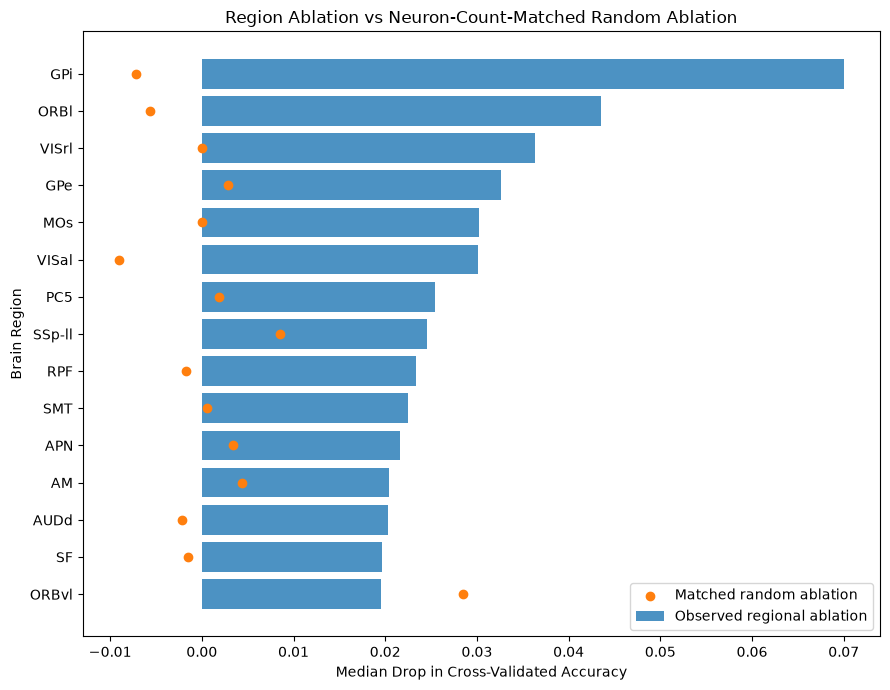

In [238]:
plot_df = (
    region_matched_stats
    .head(15)
    .sort_values(
        'observed_median_drop'
    )
)

plt.figure(figsize=(9, 7))

plt.barh(
    plot_df['acronym'],
    plot_df['observed_median_drop'],
    alpha=0.8,
    label='Observed regional ablation'
)

plt.scatter(
    plot_df['null_median_drop'],
    plot_df['acronym'],
    marker='o',
    label='Matched random ablation'
)

plt.xlabel(
    'Median Drop in Cross-Validated Accuracy'
)

plt.ylabel(
    'Brain Region'
)

plt.title(
    'Region Ablation vs Neuron-Count-Matched Random Ablation'
)

plt.legend()

plt.tight_layout()

plt.show()